# TD5 - Traitement statistique, géostatistiques et approche systèmes - ENSG 2A (S7)

## Objectifs

Ce notebook reproduit en Python les analyses géostatistiques du TD5 réalisées dans le logiciel **SKUA-Gocad**, en utilisant les bibliothèques Python suivantes :

- **pandas** >> chargement et exploration des données CSV
- **matplotlib** >> visualisation des données
- **numpy** >> calculs statistiques

## Données

Les données utilisées sont le jeu de données **Jura** :

- **259 échantillons** de sol en 2D
- **Coordonnées** X et Y en **kilomètres**
- **Variables** : Cd, Co, Cr, Cu, Ni, Zn, Pb
- **Variable étudiée** : Pb (Plomb) en mg/kg

## 1. Chargement des données

Les données de **Jura** sont chargées avec la bibliothèque **pandas** depuis un fichier CSV contenant les coordonnées **X**, **Y** et les propriétés géochimiques **(Cd, Co, Cr, Cu, Ni, Zn, Pb)**.
La variable étudiée est le **Plomb (Pb)** en mg/kg.

In [36]:
# ---- Chargement des données ----
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# Chargement des données avec le module utilitaire
data_jura = gutils.charger_donnees_jura()

# ---- Afficher les premières lignes ----
print("Trois premières lignes")
display(data_jura.head(3))

# ---- Afficher les dernières lignes ----
print("Deux dernières lignes")
display(data_jura.tail(2))

data_jura.info()


Trois premières lignes


,X,Y,Landuse,RockType,Cd,Co,Cr,Cu,Ni,Pb,Zn
0,2.386,3.077,3,3,1.740,9.32,38.32,25.72,21.32,77.36,92.56
1,2.544,1.972,2,2,1.335,10.00,40.20,24.76,29.72,77.88,73.56
2,2.807,3.347,2,3,1.610,10.60,47.00,8.88,21.40,30.80,64.80


Deux dernières lignes


,X,Y,Landuse,RockType,Cd,Co,Cr,Cu,Ni,Pb,Zn
257,4.610,3.315,1,2,1.384,12.68,30.76,7.48,20.72,48.0,46.8
258,3.605,5.345,3,3,0.849,9.04,29.48,18.40,17.56,35.0,58.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259 entries, 0 to 258
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   X         259 non-null    float64
 1   Y         259 non-null    float64
 2   Landuse   259 non-null    int64  
 3   RockType  259 non-null    int64  
 4   Cd        259 non-null    float64
 5   Co        259 non-null    float64
 6   Cr        259 non-null    float64
 7   Cu        259 non-null    float64
 8   Ni        259 non-null    float64
 9   Pb        259 non-null    float64
 10  Zn        259 non-null    float64
dtypes: float64(9), int64(2)
memory usage: 22.4 KB


## 2. Visualisation spatiale

Les points d'échantillonnage du **Plomb (Pb)** sont représentés selon leurs coordonnées **X** et **Y**, colorés selon la concentration, ce qui permet d'observer la distribution spatiale et d'identifier les zones d'enrichissement.

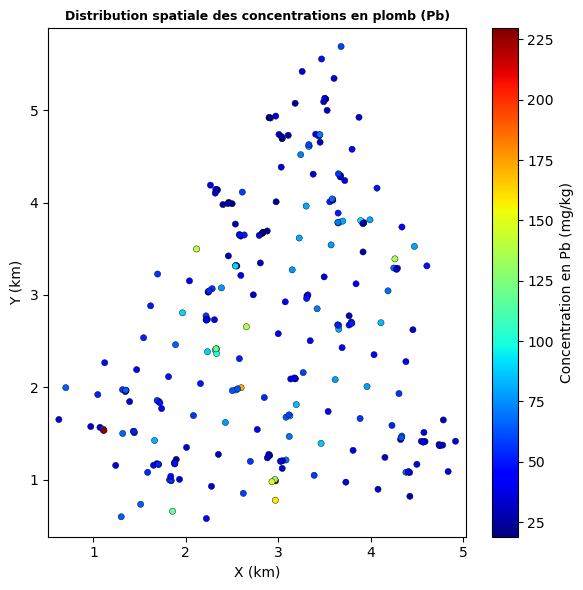

In [37]:
#----carte spatiale du plomb (Pb)----
plt.figure(figsize=(6, 6))
plt.scatter(data_jura['X'], data_jura['Y'], c=data_jura['Pb'], cmap='jet', s=20, edgecolor='k', linewidth=0.3, vmin=data_jura['Pb'].min(), vmax=data_jura['Pb'].max())
plt.colorbar(label='Concentration en Pb (mg/kg)')
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.title("Distribution spatiale des concentrations en plomb (Pb)", fontsize=9, fontweight='bold', loc='center')
plt.axis("equal") 
plt.tight_layout()  
gutils.sauvegarder_figure("fig01_distribution_pb.png") 
plt.show()

## 3. Détection et isolation des points anomaliques

Le TD5 (slide 24) demande d'identifier et d'**isoler** les points anomaliques, sans imposer de méthode particulière. On utilise la **règle de l'écart interquartile (IQR)** avec un coefficient ajusté à la taille de l'échantillon (Lin, Zhang & Tong, 2025), plutôt que le coefficient fixe k = 1,5 de la règle de Tukey classique :

$$k_n^{Chau} = \frac{\Phi^{-1}(1-0{,}25/n)}{1{,}35} - 0{,}5$$

Pour n = 259, ce coefficient vaut k ≈ 1,80. Un point est jugé anomalique si sa concentration dépasse **Q3 + k_Chau × IQR = [SEUIL] mg/kg**.

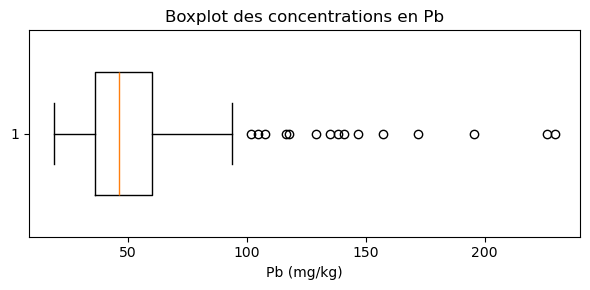

Taille d'échantillon n = 259
Coefficient ajusté k_Chau_n = 1.797
Seuil anomalique (Q3 + k_Chau_n * IQR) = 103.3 mg/kg
Nombre de points anomaliques : 14 / 259


,X,Y,RockType,Landuse,Pb
39,2.972,0.988,3,2,229.56
183,1.114,1.535,3,2,226.40
148,1.108,1.535,3,2,195.60
202,2.599,1.996,2,3,172.12
107,2.969,0.778,2,2,157.28
101,2.933,0.978,3,2,146.80
7,2.116,3.498,1,3,141.00
215,2.656,2.656,2,3,138.56
168,4.264,3.391,2,3,135.20
46,2.965,1.002,3,2,129.20


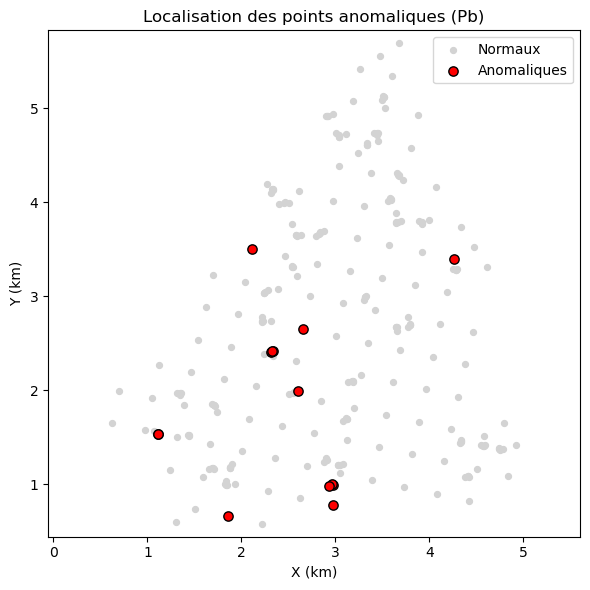

RockType
1    1.9
2    4.7
3    9.5
4    0.0
5    5.5
Name: count, dtype: float64

In [38]:
import numpy as np
from scipy.stats import norm

Pb = data_jura['Pb']
n = len(Pb)

# ---- Boxplot ----
plt.figure(figsize=(6, 3))
plt.boxplot(Pb, orientation='horizontal', widths=0.6)
plt.title("Boxplot des concentrations en Pb")
plt.xlabel("Pb (mg/kg)")
plt.tight_layout()
plt.show()

# ---- Quartiles et IQR ----
q1 = np.percentile(Pb, 25)
q3 = np.percentile(Pb, 75)
iqr = q3 - q1

# ---- Règle du Chauvenet-type boxplot (Lin, Zhang & Tong, 2025) ----
# k_Chau_n = Phi^-1(1 - 0.25/n) / 1.35 - 0.5, ajusté à la taille d'échantillon n
k_chau = norm.ppf(1 - 0.25/n) / 1.35 - 0.5
seuil_haut = q3 + k_chau * iqr

print(f"Taille d'échantillon n = {n}")
print(f"Coefficient ajusté k_Chau_n = {k_chau:.3f}")
print(f"Seuil anomalique (Q3 + k_Chau_n * IQR) = {seuil_haut:.1f} mg/kg")

# ---- Isolation des points anomaliques ----
points_anomalies = data_jura[data_jura['Pb'] > seuil_haut]
print(f"Nombre de points anomaliques : {len(points_anomalies)} / {len(data_jura)}")
display(points_anomalies[['X', 'Y', 'RockType', 'Landuse', 'Pb']].sort_values('Pb', ascending=False))

# ---- Localisation des anomalies sur la carte ----
points_normaux = data_jura[data_jura['Pb'] <= seuil_haut]
plt.figure(figsize=(6, 6))
plt.scatter(points_normaux['X'], points_normaux['Y'], c='lightgrey', s=18, label='Normaux')
plt.scatter(points_anomalies['X'], points_anomalies['Y'], c='red', s=45, edgecolor='k', label='Anomaliques')
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.title("Localisation des points anomaliques (Pb)")
plt.legend()
plt.axis("equal")
plt.tight_layout()
gutils.sauvegarder_figure("fig02_points_anomaliques.png") 
plt.show()

# ---- Explication des anomalies : lien avec le type de roche ----
compte_anomalies_par_roche = points_anomalies['RockType'].value_counts()
compte_total_par_roche = data_jura['RockType'].value_counts()
pourcentage_anomalies = (compte_anomalies_par_roche / compte_total_par_roche * 100).fillna(0).round(1)
pourcentage_anomalies

## 4. Histogramme et courbe cumulative

L'histogramme permet d'observer la distribution des concentrations en **Plomb (Pb)**, d'identifier la présence de valeurs extrêmes et d'évaluer la dispersion des concentrations. Un histogramme est construit avec **50 classes (bins)** accompagné d'une courbe cumulative.

Les statistiques descriptives (moyenne, médiane, quartiles, IQR, écart-type, variance) sont calculées directement avec **numpy** et affichées sur la courbe cumulative.

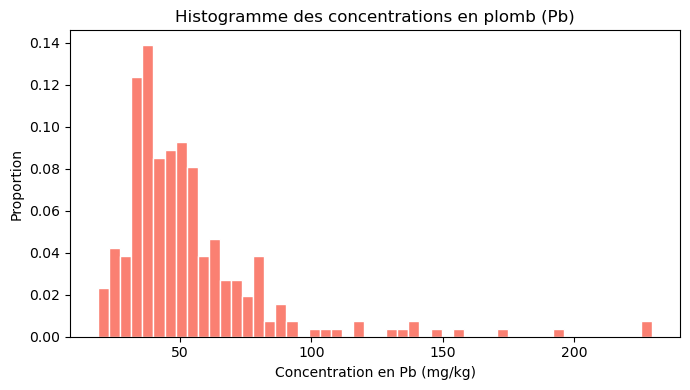

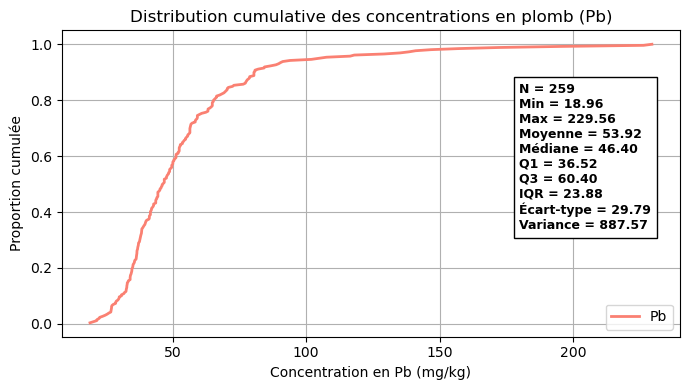

In [39]:
# ----calcul histogramme du plomb (Pb)----

Pb = data_jura['Pb']

plt.figure(figsize=(7, 4))

plt.hist(Pb, bins=50, weights=np.ones(len(Pb)) / len(Pb), color='salmon', edgecolor='white')
plt.title("Histogramme des concentrations en plomb (Pb)")
plt.xlabel("Concentration en Pb (mg/kg)")
plt.ylabel("Proportion")
plt.tight_layout()
gutils.sauvegarder_figure("fig03_histogramme_pb.png") 
plt.show()
# ----calcul statistiques du plomb (Pb)----

nombre_mesures = len(Pb)
min_value = np.min(Pb)
max_value = np.max(Pb)
moyenne_pb = np.mean(Pb)
mediane_pb = np.median(Pb)
premier_quartile = np.percentile(Pb, 25)
troisieme_quartile = np.percentile(Pb, 75)   
IQR = troisieme_quartile - premier_quartile           
ecart_type_pb = np.std(Pb, ddof=1)
variance_pb = np.var(Pb, ddof=1)
Pb_trie = np.sort(Pb)
Pb_cumulative = np.arange(1, len(Pb_trie)+1) / len(Pb_trie)

#----Distribution cumulative du plomb (Pb)----

plt.figure(figsize=(7, 4))

plt.plot(Pb_trie, Pb_cumulative, color='salmon', linewidth=2, label='Pb')
plt.title("Distribution cumulative des concentrations en plomb (Pb)")
plt.xlabel("Concentration en Pb (mg/kg)")
plt.ylabel("Proportion cumulée")
plt.legend(loc='lower right')

#----Affichage Texte statistiques sur le graphe----

text_stats = (
    f"N = {nombre_mesures}\n"
    f"Min = {min_value:.2f}\n"
    f"Max = {max_value:.2f}\n"
    f"Moyenne = {moyenne_pb:.2f}\n"
    f"Médiane = {mediane_pb:.2f}\n"
    f"Q1 = {premier_quartile:.2f}\n"
    f"Q3 = {troisieme_quartile:.2f}\n"
    f"IQR = {IQR:.2f}\n"
    f"Écart-type = {ecart_type_pb:.2f}\n"
    f"Variance = {variance_pb:.2f}"
)
plt.text(0.74, 0.35,                     
    text_stats,
    transform=plt.gca().transAxes,
    fontsize=9,
    fontweight='bold',
    bbox=dict(facecolor='white', edgecolor='black')
)
plt.grid()
plt.tight_layout()
gutils.sauvegarder_figure("fig04_courbe_cumulative_pb.png") 
plt.show()

**D'après la courbe cumulative :**

- **60%** des échantillons ont une concentration en Pb inférieure à **50 mg/kg**
- **95%** des échantillons ont une concentration en Pb inférieure à **100 mg/kg**
- Quelques valeurs extrêmes dépassent **200 mg/kg**

## 5. Mode et sensibilité au nombre de classes

Le **mode** (réalisation la plus fréquente, TD5 slide 22) est estimé par la **classe modale** de l'histogramme. Comme le recommande le TD5 (slide 23), on **fait varier le nombre de classes** (10, 30, 100) pour vérifier si une structure (mélange de populations) est réelle ou un simple artefact de discrétisation.

Mode (classe modale, 50 classes) ~ 37.9 mg/kg
Moyenne = 53.9 | Médiane = 46.4 mg/kg
=> Moyenne > Médiane > Mode : distribution étalée vers la droite (asymétrie positive).


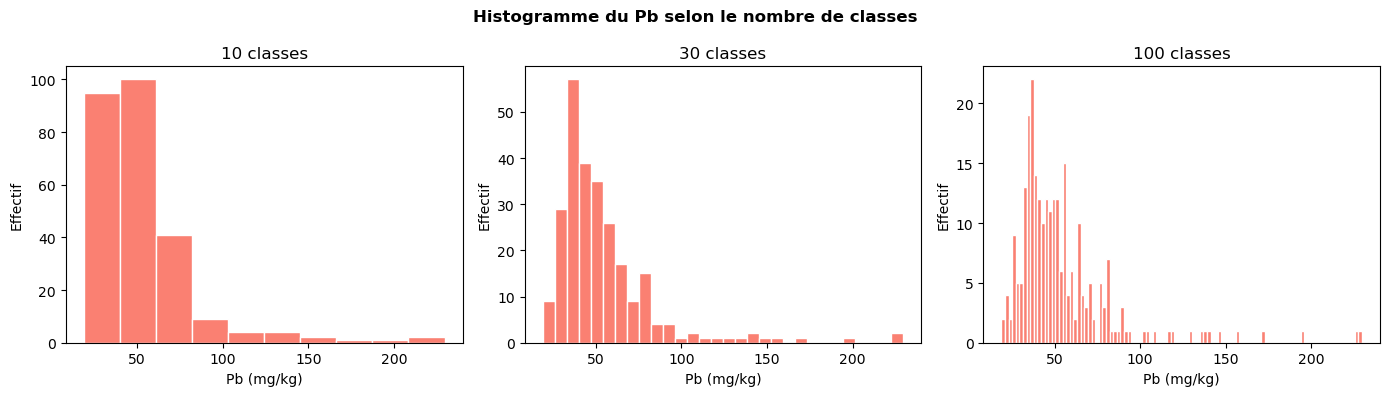

In [40]:
Pb = data_jura['Pb']

# ---- Mode : centre de la classe la plus fréquente (classe modale) ----
comptes, bords = np.histogram(Pb, bins=50)
i_mode = np.argmax(comptes)
classe_modale = (bords[i_mode] + bords[i_mode + 1]) / 2
print(f"Mode (classe modale, 50 classes) ~ {classe_modale:.1f} mg/kg")
print(f"Moyenne = {np.mean(Pb):.1f} | Médiane = {np.median(Pb):.1f} mg/kg")
print("=> Moyenne > Médiane > Mode : distribution étalée vers la droite (asymétrie positive).")

# ---- Sensibilité au nombre de classes ----
nb_classes = [10, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, nb in zip(axes, nb_classes):
    ax.hist(Pb, bins=nb, color='salmon', edgecolor='white')
    ax.set_title(f"{nb} classes")
    ax.set_xlabel("Pb (mg/kg)")
    ax.set_ylabel("Effectif")
fig.suptitle("Histogramme du Pb selon le nombre de classes", fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Analyse bivariée et multivariée — corrélations entre métaux

Le TD5 (slides 18–19, 24) demande d'étudier les **relations entre variables** (l'équivalent Jura du « poro / perm » du support). On calcule la **matrice de corrélation** entre les 7 métaux, puis on visualise les nuages de points du Pb avec les métaux les plus corrélés.

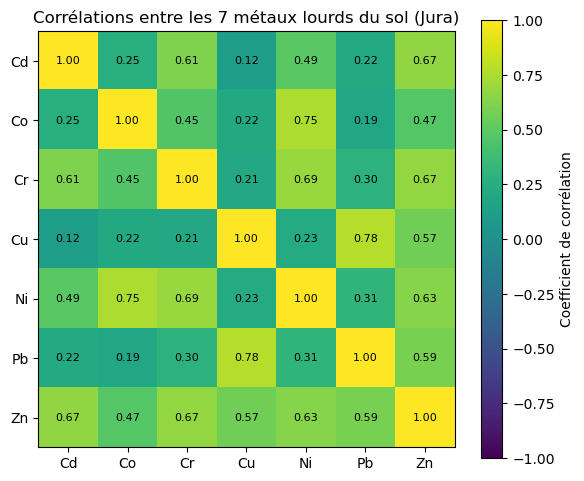

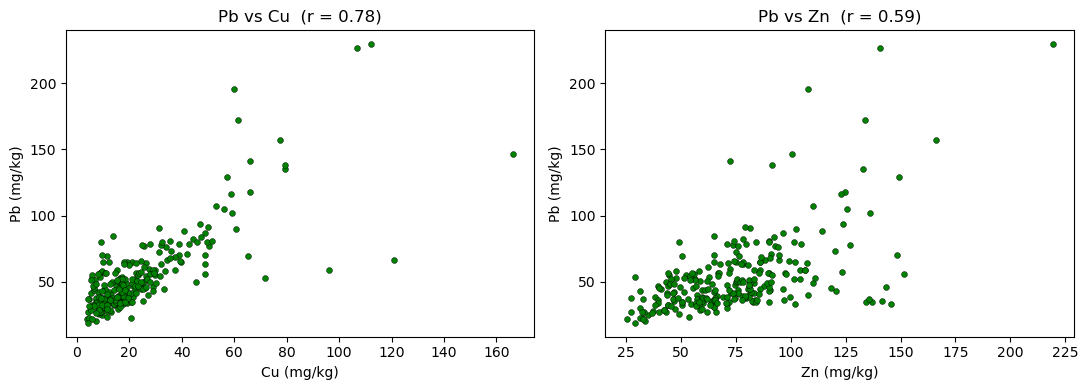

In [41]:
list_metaux = ['Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']

# ---- Matrice de corrélation (multivariée) ----
matrice_correlation = data_jura[list_metaux].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matrice_correlation, cmap='viridis', vmin=-1, vmax=1)
ax.set_xticks(range(len(list_metaux)), labels=list_metaux)
ax.set_yticks(range(len(list_metaux)), labels=list_metaux)
for i in range(len(list_metaux)):
    for j in range(len(list_metaux)):
        ax.text(j, i, f"{matrice_correlation.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)
fig.colorbar(im, label="Coefficient de corrélation")
ax.set_title("Corrélations entre les 7 métaux lourds du sol (Jura)")
plt.tight_layout()
gutils.sauvegarder_figure("fig04_correlation_multivariee") 
plt.show()

# ---- Nuages de points : Pb vs métaux les plus corrélés (bivariée) ----
metaux_correles_pb = ['Cu', 'Zn']  # métaux les plus corrélés au Pb (r = 0.78 et 0.59)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, metaux_correles_pb):
    ax.scatter(data_jura[m], data_jura['Pb'], s=18, color='green', edgecolor='k', linewidth=0.3)
    coef_correlation = data_jura[['Pb', m]].corr().iloc[0, 1]
    ax.set_xlabel(f"{m} (mg/kg)")
    ax.set_ylabel("Pb (mg/kg)")
    ax.set_title(f"Pb vs {m}  (r = {coef_correlation:.2f})")
plt.tight_layout()
plt.show()

## 7. Analyse par régions — RockType et Landuse

Le TD5 (slides 13, 20, 24) introduit la notion de **régions** = sous-ensembles homogènes. Le jeu Jura fournit deux découpages naturels : le **type de roche (RockType)** et l'**usage du sol (Landuse)**. On compare la distribution du Pb entre ces régions pour repérer des zones où la statistique est homogène en  première étape vers une **modélisation par régions**.

Statistiques du Pb par type de roche :


,count,mean,median,std
Argovien,53,41.3,36.6,17.7
Kimméridgien,85,56.4,49.6,26.4
Séquanien,63,62.9,50.4,42.1
Portlandien,3,48.0,44.0,17.9
Quaternaire,55,52.3,48.4,23.2


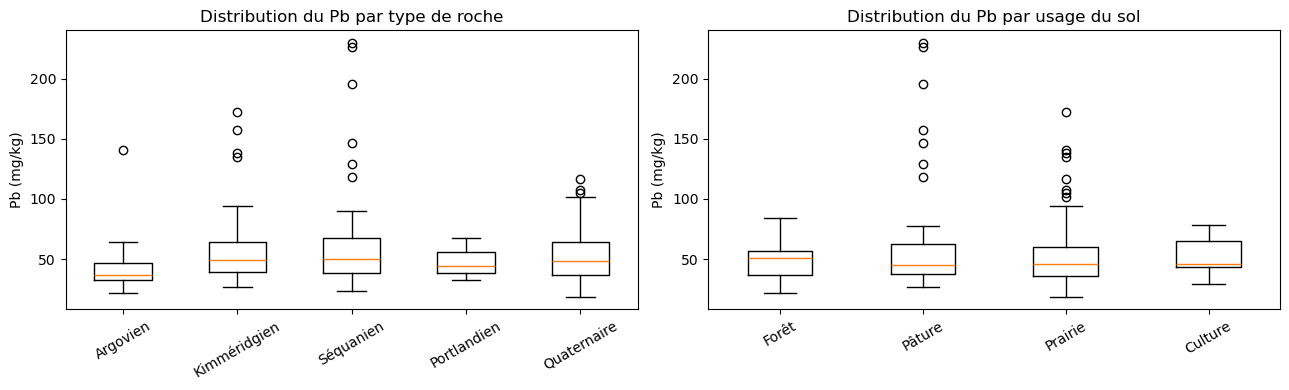

In [42]:
# ---- Libellés standard du jeu Jura ----
noms_roches = {1: 'Argovien', 2: 'Kimméridgien', 3: 'Séquanien', 4: 'Portlandien', 5: 'Quaternaire'}
noms_usages = {1: 'Forêt', 2: 'Pâture', 3: 'Prairie', 4: 'Culture'}

# ---- Statistiques du Pb par type de roche ----
stats_par_roche = data_jura.groupby('RockType')['Pb'].agg(['count', 'mean', 'median', 'std']).round(1)
stats_par_roche.index = [noms_roches.get(i, i) for i in stats_par_roche.index]
print("Statistiques du Pb par type de roche :")
display(stats_par_roche)

# ---- Boxplots du Pb par région ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom_colonne, dictionnaire_noms, titre_categorie) in zip(
    axes,
    [('RockType', noms_roches, 'type de roche'), ('Landuse', noms_usages, "usage du sol")],
):
    codes_uniques = sorted(data_jura[nom_colonne].unique())
    valeurs_pb_par_groupe = [data_jura.loc[data_jura[nom_colonne] == c, 'Pb'] for c in codes_uniques]
    ax.boxplot(valeurs_pb_par_groupe, tick_labels=[dictionnaire_noms.get(c, c) for c in codes_uniques])
    ax.set_ylabel("Pb (mg/kg)")
    ax.set_title(f"Distribution du Pb par {titre_categorie}")
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
gutils.sauvegarder_figure("fig05_regions_rocktype_landuse.png") 
plt.show()

## 8. Interprétation — distribution du Pb par régions

**Par type de roche (RockType) :** le Séquanien a la médiane la plus haute et la plus grande dispersion (seules valeurs extrêmes >200 mg/kg), tandis que l'Argovien est le plus homogène avec la médiane la plus basse (~37 mg/kg). Le type de roche influence donc clairement la teneur en Pb.

**Par usage du sol (Landuse) :** les 4 catégories ont des médianes proches (~45-50 mg/kg), avec un effet nettement plus faible que le RockType.

**Conclusion :** le `RockType` est le critère de régionalisation le plus pertinent pour expliquer la variabilité du Pb.